# 3주차 · 공정 조건으로 막 두께 예측하기

**이번 실습:** 공정 조건으로 막 두께를 예측하고, 평균만 답하는 기준선과 비교합니다.  
**준비:** 데이터 안내와 파이썬 기초

이 파일 하나를 위에서부터 순서대로 실행합니다. 주차 안의 이론 차시마다 별도 코드를 실행할 필요는 없습니다. 오른쪽 위 커널은 **Python (semi-ai)**로 고릅니다. `#` 뒤의 한국어 주석을 한 줄씩 읽고 실행해 주세요. 데이터는 교육용 합성 자료입니다.

## 0. 실습 폴더 준비

VS Code와 Colab 어디서 열어도 `data` 폴더를 찾도록 실습 폴더 위치를 정합니다. Colab에서는 처음 한 번 실습 자료를 내려받습니다.

In [ ]:
import sys, subprocess  # 실행 환경 확인과 명령 실행 도구입니다.
from pathlib import Path  # 파일 위치 도구입니다.
if "google.colab" in sys.modules:  # Colab에서 실행 중이라면
    folder = Path("/content/semiconductor_ai_beginner")  # 실습 자료를 둘 위치입니다.
    if not folder.exists():  # 아직 내려받지 않았다면
        subprocess.run(["git", "clone", "-q", "https://github.com/SeokJH-TAs/semiconductor_ai_beginner.git", str(folder)], check=True)  # 실습 자료 전체를 내려받습니다.
else:  # VS Code 등 내 컴퓨터에서 실행 중이라면
    folder = Path.cwd()  # 현재 폴더입니다.
    if folder.name == "notebooks":  # 노트북 폴더 안이라면
        folder = folder.parent  # 실습 전체 폴더로 올라갑니다.
print(folder)  # 실습 폴더 위치를 확인합니다.

## 1. 입력 세 개와 정답 고르기

목표는 공정 조건으로 공정 후 막 두께를 예상하는 것입니다. 정답 thickness_nm과 검사 라벨 defect는 입력에 넣지 않습니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [1]:
from pathlib import Path  # 폴더와 파일의 위치를 다루는 도구를 꺼냅니다.
import pandas as pd  # 표를 읽는 pandas 도구를 pd라는 짧은 이름으로 부릅니다.
data = pd.read_csv(folder / "data" / "process.csv")  # data 폴더의 표를 읽어 data에 담습니다.
print(data.head())  # 표의 첫 다섯 줄을 화면에 보여 줍니다.

X = data[["temperature_c", "gas_flow_sccm", "rf_power_w"]]  # 공정 중 알 수 있는 세 열입니다.
y = data["thickness_nm"]  # 예측할 공정 후 두께입니다.

  sample_id  temperature_c  pressure_torr  gas_flow_sccm  rf_power_w  \
0      W001        413.698          1.664        110.439     221.019   
1      W002        396.944          1.637        100.881     214.638   
2      W003        417.930          1.186        119.415     182.867   
3      W004        409.868          1.425        105.852     256.782   
4      W005        379.709          1.485         91.803     188.240   

   thickness_nm  defect  
0       104.018       1  
1        97.325       0  
2       107.485       1  
3       100.399       0  
4        92.937       0  


**실행 후 확인:** 입력은 (240, 3), 정답은 240개입니다.

## 2. 연습 문제와 새 문제 나누기

test_size=0.25는 전체의 25%를 시험용으로 남긴다는 뜻입니다. 이 예제는 서로 독립으로 생성한 기록이므로 무작위 분할합니다. 실제 로트·시간 기록은 다른 분할이 필요할 수 있습니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [2]:
from sklearn.model_selection import train_test_split  # 데이터를 나누는 도구입니다.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)  # 75%와 25%로 나눕니다.
print(len(X_train), len(X_test))  # 두 묶음의 크기를 봅니다.

180 60


**실행 후 확인:** 학습 180개, 시험 60개입니다.

## 2-1. 학습하기 전 데이터 그림

학습 자료의 온도와 실제 두께만 먼저 그립니다. 아직 모델이 만든 예측선은 없습니다. 입력에는 온도 외에 유량·전력도 있으므로 점들이 한 직선 위에 정확히 놓일 필요는 없습니다.

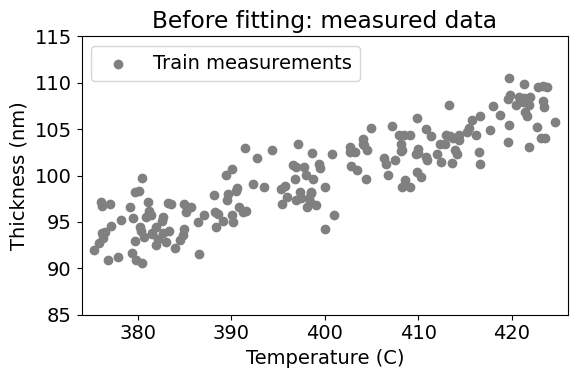

In [3]:
import matplotlib.pyplot as plt  # 그림 도구입니다.
plt.rcParams["font.size"] = 14  # 발표 화면에서도 축 글자를 읽기 쉽게 키웁니다.
plt.figure(figsize=(6, 4))  # 비교용 그림의 크기입니다.
plt.scatter(X_train["temperature_c"], y_train, color="gray", label="Train measurements")  # 학습 기록입니다.
plt.xlim(374, 426)  # 뒤의 예측선 그림과 같은 범위입니다.
plt.ylim(85, 115)  # 두께 범위도 같게 둡니다.
plt.xlabel("Temperature (C)")  # 가로축은 온도입니다.
plt.ylabel("Thickness (nm)")  # 세로축은 두께입니다.
plt.title("Before fitting: measured data")  # 학습 전 자료입니다.
plt.legend()  # 점의 뜻을 보여 줍니다.
plt.tight_layout()  # 그림 여백을 맞춥니다.
plt.show()  # 그림을 보여 줍니다.

## 3. 세 입력으로 학습하고 채점하기

이 모델은 원래 단위 그대로 학습합니다. 계수의 절댓값만으로 다른 단위 특징의 중요도를 비교하면 안 됩니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [4]:
from sklearn.linear_model import LinearRegression  # 직선 회귀 학습 도구입니다.
from sklearn.metrics import mean_squared_error, r2_score  # 오차와 R제곱을 구하는 도구입니다.
import numpy as np  # 제곱근 계산 도구입니다.
model = LinearRegression()  # 회귀 모델을 준비합니다.
model.fit(X_train, y_train)  # 학습용 기록만으로 규칙을 배웁니다.
prediction = model.predict(X_test)  # 처음 보는 시험 입력의 두께를 예상합니다.
print(np.sqrt(mean_squared_error(y_test, prediction)))  # 시험 RMSE, 단위는 nm입니다.
print(r2_score(y_test, prediction))  # 평균 예측과 비교한 R제곱입니다.

1.1756277712923302
0.9264127424757903


**실행 후 확인:** RMSE는 약 1nm대이고 R²는 1보다 작습니다. R²는 음수도 가능하며 인과관계를 뜻하지 않습니다.

## 4. 평균만 답하는 모델과 비교하기

기준선도 시험 정답의 평균을 미리 보면 안 됩니다. 학습 정답의 평균을 모든 새 입력에 똑같이 답하게 합니다.

먼저 주석을 한 줄씩 읽고, 결과를 예상한 다음 실행해 주세요.

In [5]:
baseline = np.repeat(y_train.mean(), len(y_test))  # 학습 정답 평균을 시험 개수만큼 반복합니다.
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline))  # 기준선의 시험 RMSE입니다.
print(baseline_rmse)  # 학습한 모델의 RMSE와 비교합니다.

4.3509970696062545


**실행 후 확인:** 평균만 답하는 기준선의 오차가 더 큽니다.

## 5. 학습한 회귀선 그리기

입력이 세 개여서 평면 그림 한 장으로 모든 조합을 그릴 수는 없습니다. **유량과 전력을 학습 자료의 평균으로 고정**하고 온도만 바꿔 모델의 예측을 그립니다. 이것은 같은 다중 회귀 모델의 한 단면입니다. 회색 점에는 서로 다른 유량·전력 조건도 포함되어 있으므로 선과의 차이가 그대로 예측 오차는 아닙니다.

`X_train.columns`를 사용하므로 앞에서 전력 열을 빼는 연습을 해도 같은 코드로 실행됩니다.

In [6]:
temperature_line = np.linspace(375, 425, 50)  # 온도를 고르게 50개 만듭니다.
line_input = pd.DataFrame(index=range(50), columns=X_train.columns)  # 모델과 같은 입력 열입니다.
for column in X_train.columns:  # 입력 열을 하나씩 꺼냅니다.
    line_input[column] = X_train[column].mean()  # 각 열을 학습 평균으로 채웁니다.
line_input["temperature_c"] = temperature_line  # 온도만 바꾸고 나머지는 고정합니다.
line_prediction = model.predict(line_input)  # 이 조건에서 모델이 예측한 두께입니다.
print(line_input.head(3))  # 고정한 조건과 바뀌는 온도를 봅니다.
print(line_prediction[:3])  # 선 위의 앞 세 예측값입니다.

   temperature_c  gas_flow_sccm  rf_power_w
0     375.000000       115.9566  216.586033
1     376.020408       115.9566  216.586033
2     377.040816       115.9566  216.586033
[92.77463227 93.07729951 93.37996675]


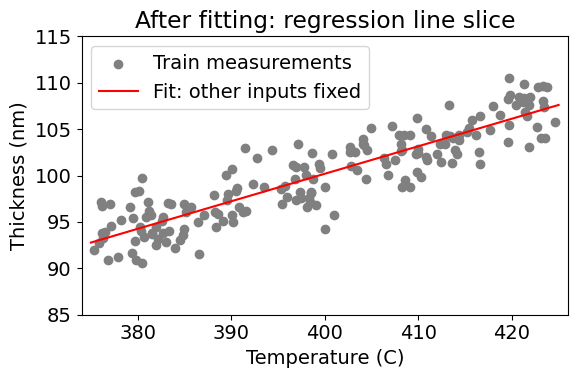

In [7]:
plt.figure(figsize=(6, 4))  # 학습 전 그림과 같은 크기입니다.
plt.scatter(X_train["temperature_c"], y_train, color="gray", label="Train measurements")  # 같은 측정 점입니다.
plt.plot(temperature_line, line_prediction, color="red", label="Fit: other inputs fixed")  # 예측선입니다.
plt.xlim(374, 426)  # 학습 전 그림과 같은 온도 범위입니다.
plt.ylim(85, 115)  # 학습 전 그림과 같은 두께 범위입니다.
plt.xlabel("Temperature (C)")  # 가로축 이름입니다.
plt.ylabel("Thickness (nm)")  # 세로축 이름입니다.
plt.title("After fitting: regression line slice")  # 학습한 모델의 한 단면입니다.
plt.legend()  # 점과 선의 뜻입니다.
plt.tight_layout()  # 글자 여백을 맞춥니다.
plt.show()  # 그림을 보여 줍니다.

## 6. 시험 자료에서 실제값과 예측값 비교하기

이번에는 시험 행마다 **실제 온도·유량·전력을 모두 입력**한 `prediction`을 봅니다. 가로축은 실제 두께, 세로축은 예측 두께입니다. 점이 대각선에 가까울수록 두 값이 비슷합니다. 대각선은 모델이 학습한 회귀선이 아니라 **실제값=예측값인 기준선**입니다.

     actual_nm  predicted_nm
24     104.813    104.162232
6      106.551    104.488154
93      99.964     99.409317
109    105.160    104.055926
104    105.853    105.332130


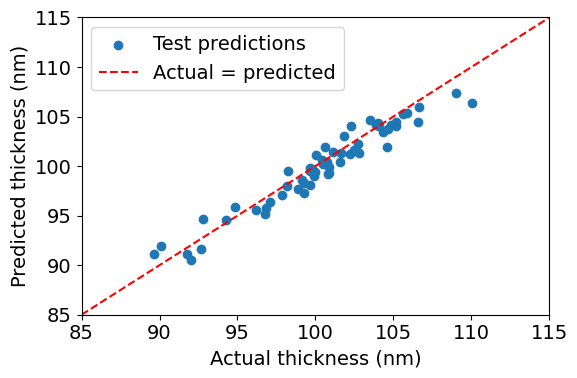

In [8]:
comparison = pd.DataFrame({"actual_nm": y_test, "predicted_nm": prediction})  # 실제값과 예측값을 나란히 둡니다.
print(comparison.head())  # 같은 행의 두 숫자를 비교합니다.
plt.figure(figsize=(6, 4))  # 새 그림입니다.
plt.scatter(y_test, prediction, label="Test predictions")  # 시험 예측을 점으로 그립니다.
plt.plot([85, 115], [85, 115], "r--", label="Actual = predicted")  # 정확히 맞은 위치의 기준선입니다.
plt.xlim(85, 115)  # 두 축의 범위를 맞춥니다.
plt.ylim(85, 115)  # 세로축도 같은 범위입니다.
plt.xlabel("Actual thickness (nm)")  # 실제 두께입니다.
plt.ylabel("Predicted thickness (nm)")  # 예측 두께입니다.
plt.legend()  # 그림의 뜻입니다.
plt.tight_layout()  # 글자 여백을 맞춥니다.
plt.show()  # 결과를 보여 줍니다.

## 직접 바꾸기

첫 구역의 입력 목록에서 `rf_power_w`를 빼고 위에서부터 다시 실행하세요. 입력 하나를 뺄 때 시험 오차가 어떻게 달라지나요?

**해설:** 이 합성 자료에서는 전력도 두께 생성에 영향을 주므로 입력에서 빼면 보통 오차가 커집니다. 시험 점수를 보며 계속 설정을 고르면 시험의 의미를 잃습니다. 여러 설정 선택은 6주차의 검증용 묶음으로 연습합니다.

## 말로 정리하기

한 행의 뜻, 입력 세 열, 정답 한 열, 모델 RMSE와 기준선 RMSE를 설명하면 이번 실습은 끝입니다. 최소제곱 공식을 따로 코딩하는 과제는 없습니다.